# 04 · Collision severity model: KSI vs slight

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryam843/uk-road-accident-analytics/blob/main/notebooks/04_severity_model.ipynb)

**Question:** given what is known *before* a collision happens (when, where, what kind of road,
light and weather), how well can we rank collisions by their chance of being **KSI** (at least
one person killed or seriously injured)?

**Target:** `ksi = 1` if collision severity is fatal or serious, `0` if slight (collision level).

**Splits (locked, by year):** train 2005-2015, validation 2016, test 2017-2019. The test years
are used once, at the end. The validation year is used for early stopping, the hyperparameter
search and the decision threshold.

**Metrics:** KSI is the minority class (notebook 01 prints its share), so accuracy is misleading:
predicting "slight" for everything already scores high. The headline metric is **PR-AUC** (average precision). Also
reported: ROC-AUC, balanced accuracy, macro-F1, and KSI recall/precision at a threshold chosen
on 2016. Accuracy is shown only next to the majority-class baseline.

Results: **TBD (run notebooks/04_severity_model.ipynb)**.

## Features and exclusions

**Used (pre-event only):** hour, weekday, month, speed limit, road type, first road class,
junction detail (`junction_detail_historic`, consistent across 2005-2019), light conditions,
weather, road surface, urban/rural, and region (mapped from police force).

**Ablation only:** number of vehicles. It is fixed at the moment of impact rather than known
in advance, so it is reported separately and never in the main model.

**Excluded, with reasons:** the table printed by the next code cell comes from
`src/features.py::EXCLUDED_FROM_MODEL`. The most important exclusions:
- `did_police_officer_attend_scene_of_collision`: decided after the collision, and police
  attend serious collisions more often, so it leaks the answer.
- `number_of_casualties`: an outcome; more casualties means more chances that one is KSI.
- everything from the casualty table: it describes the injuries, i.e. the label itself.
- `collision_adjusted_*` and `collision_injury_based`: derived from, or describing, how the
  severity label was recorded.

**Missing values:** in the cleaned data, missing codes are NaN. They are never a category
there. Inside the model, the one-hot encoder adds an explicit "missing" indicator column per
feature.

In [ ]:
# Setup: works from the repo root, from notebooks/, or on Google Colab.
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src/config.py").exists():
    if not Path("uk-road-accident-analytics").exists():
        !git clone -q https://github.com/maryam843/uk-road-accident-analytics.git
    %cd uk-road-accident-analytics
    %pip install -q -r requirements.txt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [ ]:
import logging

import matplotlib.pyplot as plt
import pandas as pd

from src import clean, config, evaluate

config.setup_logging(logging.INFO)
evaluate.apply_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

DATA_DIR = config.get_data_dir()
RAW, PROCESSED = DATA_DIR / "raw", DATA_DIR / "processed"
if not (PROCESSED / config.COLLISIONS_PARQUET).exists():
    # Fresh runtime (e.g. Colab): download (several GB) and clean. Takes a while, once.
    from src import download

    download.main([])
    clean.run()
print("DATA_DIR =", DATA_DIR)

DATA_DIR = data


In [ ]:
import lightgbm as lgb
import numpy as np
import shap
from scipy.stats import loguniform, randint, uniform
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.model_selection import ParameterSampler

from src import features

display(pd.Series(features.EXCLUDED_FROM_MODEL, name="reason").rename_axis("excluded field").to_frame())

/usr/local/lib/python3.11/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,reason
excluded field,
did_police_officer_attend_scene_of_collision,recorded after the event; police are more like...
number_of_casualties,outcome of the collision; more casualties mean...
casualty table (all fields),"describes the injured people, i.e. the outcome..."
collision_adjusted_serious / collision_adjusted_slight,derived from the severity label
collision_injury_based,describes how severity was recorded (CRASH/COP...
enhanced_collision_severity,"outcome, and only collected from 2023"
police_force (raw code),replaced by region: Scottish codes changed in ...
"special_conditions_at_site, carriageway_hazards",not in the agreed feature list
latitude / longitude,not in the agreed feature list; spatial work i...


In [ ]:
SOURCE_COLUMNS = ["collision_index", "collision_year", "date", "hour", "speed_limit", "police_force",
                  "number_of_vehicles", "ksi", *[c for c in features.CATEGORICAL_FEATURES.values()
                                                if c.endswith("_label")]]
collisions = pd.read_parquet(PROCESSED / config.COLLISIONS_PARQUET, columns=SOURCE_COLUMNS)
frame = features.build_model_frame(collisions)
del collisions

splits = features.split_by_year(frame)  # asserts no collision index is in two splits
features.assert_disjoint(splits)
print("No collision index appears in more than one split.")
split_summary = pd.DataFrame({name: {"years": f"{s['year'].min()}-{s['year'].max()}", "rows": len(s),
                                     "ksi_share": s["ksi"].mean()} for name, s in splits.items()}).T
display(split_summary)

No collision index appears in more than one split.


,years,rows,ksi_share
train,2005-2015,1780653,0.149
valid,2016-2016,136621,0.170
test,2017-2019,370153,0.198


## Known label shift: CRASH/COPA injury-based reporting

From 2016, many police forces moved to injury-based severity reporting (CRASH, and COPA in the
Metropolitan Police). An officer now records the injury, and the system derives the severity,
which classifies more casualties as *serious* than officer judgement did. So the KSI share
rises in 2016-2019 partly because the **label definition changed**, not only because roads got
more dangerous.

What this means here:
- The model is trained on 2005-2015 labels (mostly officer-judged) and tested on 2017-2019
  labels (largely injury-based). Precision and recall at a fixed threshold will drift.
  Metrics are therefore also reported **per test year**.
- PR-AUC depends on the base rate. A higher test KSI share alone raises PR-AUC, so compare each
  model with the base rate (= PR-AUC of a no-skill model) in the same year.
- DfT's adjustment variables correct *counts* for trend charts. They are not used as training
  labels, because they are probabilities attached to individual records rather than observed
  outcomes.

17:23:46 INFO src.evaluate: Saved figure reports/figures/04_ksi_share_by_year.png


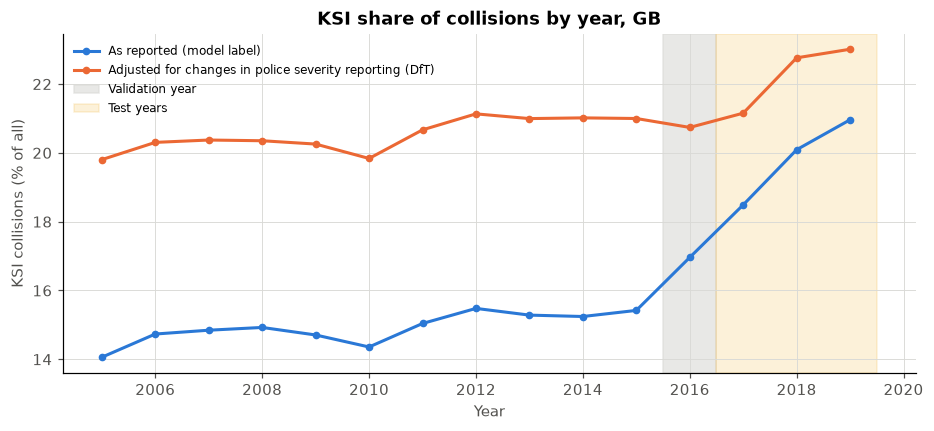

In [ ]:
yearly = pd.read_parquet(PROCESSED / config.YEARLY_PARQUET)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(yearly.index, 100 * yearly["ksi_collisions"] / yearly["collisions"], marker="o", markersize=4,
        label="As reported (model label)")
ax.plot(yearly.index, 100 * yearly["ksi_collisions_adjusted"] / yearly["collisions"], marker="o",
        markersize=4, label="Adjusted for changes in police severity reporting (DfT)")
ax.axvspan(2015.5, 2016.5, color="#d9d9d6", alpha=0.6, label="Validation year")
ax.axvspan(2016.5, 2019.5, color="#eda100", alpha=0.15, label="Test years")
ax.set_title("KSI share of collisions by year, GB")
ax.set_ylabel("KSI collisions (% of all)")
ax.set_xlabel("Year")
ax.legend(fontsize=8)
evaluate.save_fig(fig, "04_ksi_share_by_year")
plt.show()

## Preprocessing: one explicit ColumnTransformer

In [ ]:
CAT = list(features.CATEGORICAL_FEATURES)
NUM_ABLATION = features.ABLATION_NUMERIC_FEATURES

pre = features.make_preprocessor(CAT)
X_train = pre.fit_transform(splits["train"][CAT]).astype(np.float32).tocsr()
X_valid = pre.transform(splits["valid"][CAT]).astype(np.float32).tocsr()
X_test = pre.transform(splits["test"][CAT]).astype(np.float32).tocsr()
y_train, y_valid, y_test = (splits[k]["ksi"].to_numpy() for k in ("train", "valid", "test"))
year_test = splits["test"]["year"].to_numpy()

feature_names = features.check_feature_coverage(pre, CAT)  # asserts every feature is present
print(f"{len(CAT)} input features -> {len(feature_names)} encoded columns; "
      f"train {X_train.shape}, valid {X_valid.shape}, test {X_test.shape}")

12 input features -> 107 encoded columns; train (1780653, 107), valid (136621, 107), test (370153, 107)


## Baselines and logistic regression

In [ ]:
probas = {"valid": {}, "test": {}}
for name, model in {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Dummy (stratified)": DummyClassifier(strategy="stratified", random_state=config.RANDOM_STATE),
    "Logistic regression (balanced)": LogisticRegression(class_weight="balanced", max_iter=2000,
                                                         random_state=config.RANDOM_STATE),
}.items():
    model.fit(X_train, y_train)
    probas["valid"][name] = model.predict_proba(X_valid)[:, 1]
    probas["test"][name] = model.predict_proba(X_test)[:, 1]
    if name.startswith("Logistic"):
        logreg = model
    print(f"{name}: validation PR-AUC = {average_precision_score(y_valid, probas['valid'][name]):.4f}")

Dummy (most frequent): validation PR-AUC = 0.1696


Dummy (stratified): validation PR-AUC = 0.1706


Logistic regression (balanced): validation PR-AUC = 0.2406


## LightGBM: class weighting, early stopping and a random search on 2016

Each configuration is trained on 2005-2015 with `class_weight="balanced"`. Training stops early
when validation (2016) average precision has not improved for 50 rounds. Configurations are then
ranked by 2016 PR-AUC. The test years are not touched.

Because 2016 is used both for early stopping and for choosing the configuration, the validation
score of the winner is slightly optimistic. That is why the test set exists.

In [ ]:
N_SEARCH = 25
SPACE = {
    "num_leaves": randint(15, 256),
    "learning_rate": loguniform(0.02, 0.2),
    "min_child_samples": randint(20, 1000),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.5, 0.5),
    "reg_lambda": loguniform(1e-3, 10),
}


def fit_lgbm(params, X_tr, y_tr, X_va, y_va):
    model = lgb.LGBMClassifier(n_estimators=3000, class_weight="balanced", subsample_freq=1,
                               metric="average_precision", random_state=config.RANDOM_STATE,
                               n_jobs=-1, verbose=-1, **params)
    model.fit(X_tr, y_tr, eval_X=(X_va,), eval_y=(y_va,),
              callbacks=[lgb.early_stopping(50, first_metric_only=True, verbose=False)])
    return model


search_rows = []
best_score, best_model, best_params = -np.inf, None, None
for params in ParameterSampler(SPACE, n_iter=N_SEARCH, random_state=config.RANDOM_STATE):
    model = fit_lgbm(params, X_train, y_train, X_valid, y_valid)
    score = average_precision_score(y_valid, model.predict_proba(X_valid)[:, 1])
    search_rows.append({**params, "best_iteration": model.best_iteration_, "valid_pr_auc": score})
    if score > best_score:
        best_score, best_model, best_params = score, model, params
search = pd.DataFrame(search_rows).sort_values("valid_pr_auc", ascending=False)
display(search.head(10).style.format(precision=4))
print(f"{len(search)} configurations tried; best 2016 PR-AUC = {best_score:.4f} "
      f"at {best_model.best_iteration_} trees")
probas["valid"]["LightGBM (tuned)"] = best_model.predict_proba(X_valid)[:, 1]
probas["test"]["LightGBM (tuned)"] = best_model.predict_proba(X_test)[:, 1]

,colsample_bytree,learning_rate,min_child_samples,num_leaves,reg_lambda,subsample,best_iteration,valid_pr_auc
19,0.7138,0.0212,480,193,0.0013,0.8546,252,0.2523
20,0.6572,0.0645,753,243,0.0099,0.7642,65,0.2522
4,0.6999,0.0223,719,222,0.0085,0.6362,265,0.2522
10,0.9211,0.0563,221,204,5.0890,0.8909,95,0.2520
24,0.6361,0.0889,652,130,0.0257,0.7219,105,0.2520
3,0.5917,0.0403,41,250,0.0012,0.8099,81,0.2520
9,0.8777,0.0532,585,120,0.1866,0.6125,182,0.2519
1,0.5780,0.0229,107,131,0.2538,0.8832,247,0.2519
7,0.6927,0.0207,917,98,0.0092,0.8733,293,0.2519
21,0.8778,0.0339,179,85,0.0144,0.6645,341,0.2519


25 configurations tried; best 2016 PR-AUC = 0.2523 at 252 trees


## Test results (2017-2019), threshold chosen on 2016

In [ ]:
thresholds = {name: (evaluate.choose_threshold(y_valid, p) if not name.startswith("Dummy") else 0.5)
              for name, p in probas["valid"].items()}
rows = []
for name, p_test in probas["test"].items():
    rows.append({"model": name, "period": "Validation 2016",
                 **evaluate.classification_metrics(y_valid, probas["valid"][name], thresholds[name])})
    rows.append({"model": name, "period": "Test 2017-2019",
                 **evaluate.classification_metrics(y_test, p_test, thresholds[name])})
    for year in (2017, 2018, 2019):
        mask = year_test == year
        rows.append({"model": name, "period": f"Test {year}",
                     **evaluate.classification_metrics(y_test[mask], p_test[mask], thresholds[name])})
results = pd.DataFrame(rows)
SHOW = ["pr_auc", "ksi_share", "roc_auc", "balanced_accuracy", "macro_f1", "ksi_recall",
        "ksi_precision", "accuracy", "majority_baseline_accuracy", "threshold"]
display(results.set_index(["period", "model"])[SHOW].sort_index(level=0, sort_remaining=False)
        .style.format("{:.4f}"))
print("ksi_share = base rate = PR-AUC of a no-skill model in that period.")

ksi_share = base rate = PR-AUC of a no-skill model in that period.


LightGBM (tuned), test 2017-2019, threshold 0.480 (chosen on 2016):


,predicted slight,predicted KSI
actual slight,"170,072","126,772"
actual KSI,"31,206","42,103"


17:32:06 INFO src.evaluate: Saved figure reports/figures/04_pr_curves_test.png


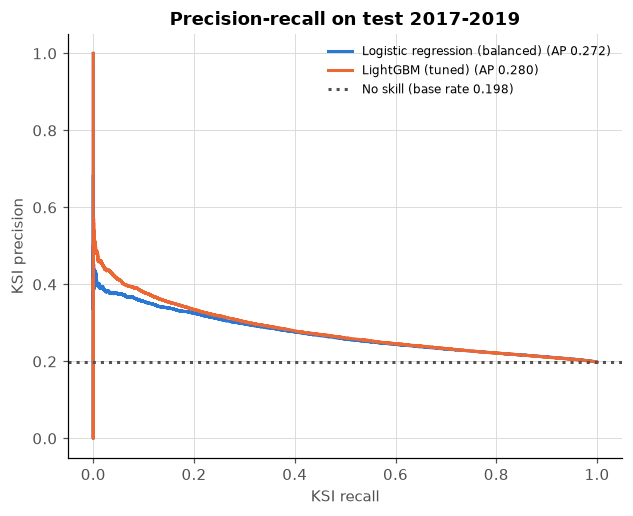

In [ ]:
best_name = "LightGBM (tuned)"
cm_row = results[(results["model"] == best_name) & (results["period"] == "Test 2017-2019")].iloc[0]
cm = pd.DataFrame([[cm_row["tn"], cm_row["fp"]], [cm_row["fn"], cm_row["tp"]]],
                  index=["actual slight", "actual KSI"], columns=["predicted slight", "predicted KSI"])
print(f"{best_name}, test 2017-2019, threshold {cm_row['threshold']:.3f} (chosen on 2016):")
display(cm.style.format("{:,.0f}"))

fig, ax = plt.subplots(figsize=(6.5, 5))
for name in ["Logistic regression (balanced)", "LightGBM (tuned)"]:
    prec, rec, _ = precision_recall_curve(y_test, probas["test"][name])
    ax.plot(rec, prec, label=f"{name} (AP {average_precision_score(y_test, probas['test'][name]):.3f})")
ax.axhline(y_test.mean(), color="#52514e", linestyle=":", label=f"No skill (base rate {y_test.mean():.3f})")
ax.set_xlabel("KSI recall")
ax.set_ylabel("KSI precision")
ax.set_title("Precision-recall on test 2017-2019")
ax.legend(fontsize=8)
evaluate.save_fig(fig, "04_pr_curves_test")
plt.show()

## Ablation: adding the number of vehicles

In [ ]:
pre_abl = features.make_preprocessor(CAT, NUM_ABLATION)
cols = CAT + NUM_ABLATION
Xa_train = pre_abl.fit_transform(splits["train"][cols]).astype(np.float32).tocsr()
Xa_valid = pre_abl.transform(splits["valid"][cols]).astype(np.float32).tocsr()
Xa_test = pre_abl.transform(splits["test"][cols]).astype(np.float32).tocsr()
features.check_feature_coverage(pre_abl, CAT, NUM_ABLATION)
abl_model = fit_lgbm(best_params, Xa_train, y_train, Xa_valid, y_valid)
ablation = pd.DataFrame({
    "valid_pr_auc": [best_score, average_precision_score(y_valid, abl_model.predict_proba(Xa_valid)[:, 1])],
    "test_pr_auc": [average_precision_score(y_test, probas["test"][best_name]),
                    average_precision_score(y_test, abl_model.predict_proba(Xa_test)[:, 1])],
}, index=["Pre-event features (main model)", "+ number_of_vehicles (ablation)"])
display(ablation.style.format("{:.4f}"))

,valid_pr_auc,test_pr_auc
Pre-event features (main model),0.2523,0.2798
+ number_of_vehicles (ablation),0.2744,0.3018


## Explaining the model: SHAP on 10,000 test rows

SHAP values (TreeExplainer) show how much each encoded feature pushed a prediction up or down,
in log-odds, *for this model*. They describe what the model learned from correlations in the
data. **They are not causal effects.** For example, a high SHAP value for "rural" does not show
that rurality causes severe injuries; it may stand in for speed, distance to hospital or
traffic mix.

The comparison with logistic-regression coefficients is a consistency check on the ranking
only: one-hot coefficients are relative to the other levels and are shrunk by regularisation.

/usr/local/lib/python3.11/dist-packages/shap/explainers/_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


17:35:40 INFO src.evaluate: Saved figure reports/figures/04_shap_beeswarm.png


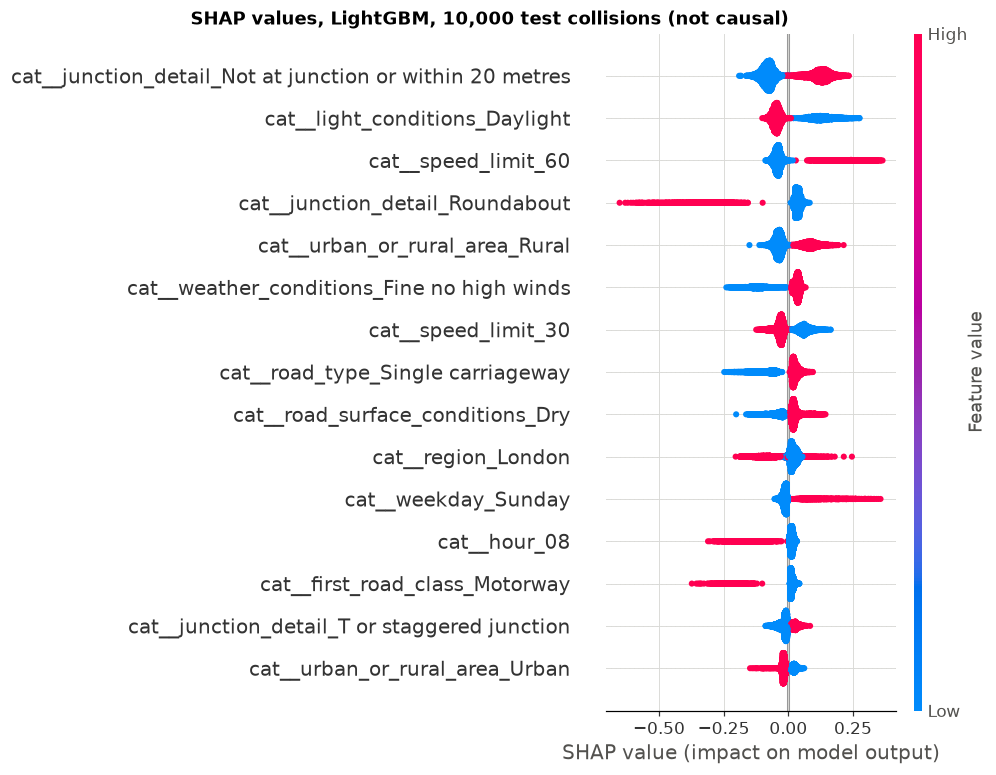

In [ ]:
rng = np.random.default_rng(config.RANDOM_STATE)
sample_idx = rng.choice(X_test.shape[0], size=min(10_000, X_test.shape[0]), replace=False)
X_shap = X_test[sample_idx].toarray()
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_shap)
if isinstance(shap_values, list):
    shap_values = shap_values[1]
if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]

plt.figure(figsize=(9, 7))
shap.summary_plot(shap_values, X_shap, feature_names=feature_names, max_display=15, show=False,
                  plot_size=None)
fig = plt.gcf()
fig.suptitle("SHAP values, LightGBM, 10,000 test collisions (not causal)", fontweight="bold", y=1.0)
evaluate.save_fig(fig, "04_shap_beeswarm")
plt.show()

In [ ]:
mean_abs = pd.Series(np.abs(shap_values).mean(axis=0), index=feature_names)
coef = pd.Series(logreg.coef_[0], index=feature_names)
lr_rank = coef.abs().rank(ascending=False).astype(int)
top10 = mean_abs.sort_values(ascending=False).head(10).to_frame("mean_abs_shap")


def shap_direction(feature):
    """Sign of corr(feature value, SHAP value): does a 1 push the prediction up or down?"""
    j = feature_names.index(feature)
    if X_shap[:, j].std() == 0:
        return "constant in sample"
    return "higher risk" if np.corrcoef(X_shap[:, j], shap_values[:, j])[0, 1] > 0 else "lower risk"


top10["shap_direction"] = [shap_direction(f) for f in top10.index]
top10["logreg_coef"] = coef.loc[top10.index]
top10["logreg_rank_by_abs_coef"] = lr_rank.loc[top10.index]
display(top10.style.format({"mean_abs_shap": "{:.4f}", "logreg_coef": "{:+.3f}"}))
print("shap_direction: sign of the correlation between the feature (0/1) and its SHAP value.")

,mean_abs_shap,shap_direction,logreg_coef,logreg_rank_by_abs_coef
cat__junction_detail_Not at junction or within 20 metres,0.0984,higher risk,+0.278,10
cat__light_conditions_Daylight,0.0714,lower risk,-0.099,52
cat__speed_limit_60,0.0657,higher risk,+0.180,24
cat__junction_detail_Roundabout,0.0595,lower risk,-0.456,1
cat__urban_or_rural_area_Rural,0.0541,higher risk,+0.001,107
cat__weather_conditions_Fine no high winds,0.0508,higher risk,+0.159,30
cat__speed_limit_30,0.0458,lower risk,-0.216,17
cat__road_type_Single carriageway,0.0440,higher risk,+0.141,34
cat__road_surface_conditions_Dry,0.0339,higher risk,+0.173,27
cat__region_London,0.0338,lower risk,-0.174,26


shap_direction: sign of the correlation between the feature (0/1) and its SHAP value.


Interpretation: **TBD (run notebooks/04_severity_model.ipynb)**. Questions to answer once
the numbers exist:
- Does the tuned LightGBM beat logistic regression by enough to justify the extra complexity?
- How far above the base rate is PR-AUC in each test year?
- How much do recall and precision drift across 2017-2019 because of the label shift?
- Do SHAP and logistic regression agree on the top drivers?